import libraries

In [16]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

load dataset

In [17]:
df = pd.read_csv("FakeNewsNet.csv")

df.head()

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


analysing news sharing behaviour

In [18]:
df['label'] = df['real'].map({
    1: 'Real',
    0: 'Fake'
})

sharing_analysis = df.groupby('label').agg({
    'tweet_num': ['sum', 'mean', 'max']
})

display(sharing_analysis)

tweet_num                   
            sum        mean    max
label                             
Fake     763651  132.693484  29060
Real    1299791   74.525027  27377

identify Most Shared News Articles

In [19]:
top_shared = df.sort_values(
    by='tweet_num',
    ascending=False
).head(10)

display(
    top_shared[['title', 'source_domain', 'tweet_num', 'label']]
)

,title,source_domain,tweet_num,label
11489,The Legislative Process,www.house.gov,29060,Fake
21215,One in Four – Congressman Joe Pitts – Medium,medium.com,27377,Real
9505,Rep. Michael McCaul (R-TX) Appears on Face the...,us3.campaign-archive1.com,21182,Real
21088,"Outlook, Office, Skype, Bing, Breaking News, a...",www.msnbc.msn.com,19863,Real
3379,interview on Fox News,www.cq.com,17746,Real
18042,Wake Up America,www.facebook.com,17548,Fake
7788,"""One Hundred Percent"" by Club for Growth Action",www.youtube.com,14885,Real
13246,"Carolyn B. Maloney on Twitter: ""Women's health...",twitter.com,14152,Real
3370,LexisNexis(R) Publisher,web.archive.org,12741,Real
9675,Democratic National Convention,web.archive.org,11714,Real


compare fake and real news sharing

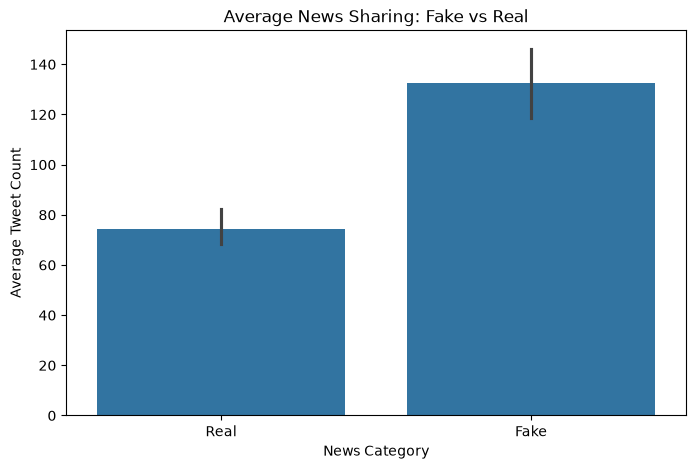

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='label',
    y='tweet_num',
    estimator='mean'
)

plt.title("Average News Sharing: Fake vs Real")
plt.xlabel("News Category")
plt.ylabel("Average Tweet Count")

plt.show()

create news-domain network

In [21]:
G = nx.Graph()

for _, row in df.iterrows():

    article = str(row['title'])
    domain = str(row['source_domain'])

    G.add_node(article, type='news')
    G.add_node(domain, type='source')

    G.add_edge(
        article,
        domain,
        weight=row['tweet_num'],
        label=row['label']
    )

print("Total Network Nodes:", G.number_of_nodes())
print("Total Network Connections:", G.number_of_edges())

Total Network Nodes: 24161
Total Network Connections: 21767


analyse network properties

In [22]:
print("Network Density:", nx.density(G))

print("Connected Components:",
      nx.number_connected_components(G))

degree_centrality = nx.degree_centrality(G)

top_nodes = sorted(
    degree_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

display(pd.DataFrame(
    top_nodes,
    columns=['Node', 'Centrality']
))

Network Density: 7.457903122842324e-05
Connected Components: 2405


,Node,Centrality
0,people.com,0.067632
1,www.dailymail.co.uk,0.038038
2,www.usmagazine.com,0.027276
3,www.etonline.com,0.026242
4,www.longroom.com,0.022724
5,en.wikipedia.org,0.022558
6,hollywoodlife.com,0.019743
7,nan,0.013535
8,www.hollywoodreporter.com,0.012748
9,www.usatoday.com,0.012459


visualise news sharing network

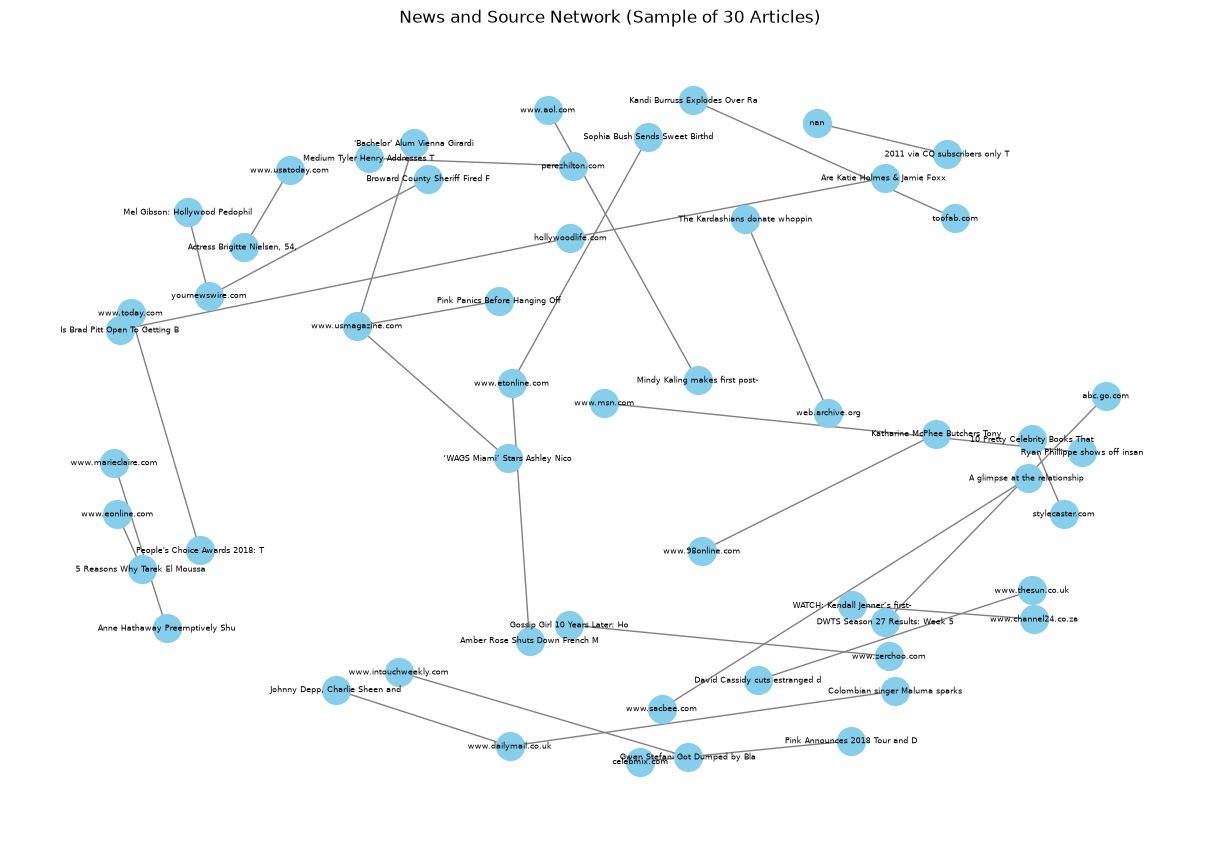

In [25]:
plt.figure(figsize=(12, 8))

small_df = df.head(30)

G_small = nx.Graph()

for _, row in small_df.iterrows():
    article = str(row['title'])[:30]
    domain = str(row['source_domain'])

    G_small.add_node(article, type='news')
    G_small.add_node(domain, type='source')

    G_small.add_edge(article, domain)

pos = nx.spring_layout(G_small, seed=42, k=0.8)

nx.draw(
    G_small,
    pos,
    with_labels=True,
    node_size=400,
    font_size=6,
    node_color='skyblue',
    edge_color='gray'
)

plt.title("News and Source Network (Sample of 30 Articles)")
plt.axis('off')
plt.show()

FINAL results

In [26]:
print("NEWS SHARING NETWORK ANALYSIS")

print("\nTotal Articles:", len(df))

print("\nFake vs Real Sharing Analysis:")
display(sharing_analysis)

print("\nTop Shared Articles:")
display(top_shared[['title', 'tweet_num', 'label']])

print("\nNetwork Nodes:", G.number_of_nodes())

print("Network Edges:", G.number_of_edges())

print("\nTop Connected Nodes:")
display(pd.DataFrame(
    top_nodes,
    columns=['Node', 'Centrality']
))

NEWS SHARING NETWORK ANALYSIS

Total Articles: 23196

Fake vs Real Sharing Analysis:


tweet_num                   
            sum        mean    max
label                             
Fake     763651  132.693484  29060
Real    1299791   74.525027  27377


Top Shared Articles:


,title,tweet_num,label
11489,The Legislative Process,29060,Fake
21215,One in Four – Congressman Joe Pitts – Medium,27377,Real
9505,Rep. Michael McCaul (R-TX) Appears on Face the...,21182,Real
21088,"Outlook, Office, Skype, Bing, Breaking News, a...",19863,Real
3379,interview on Fox News,17746,Real
18042,Wake Up America,17548,Fake
7788,"""One Hundred Percent"" by Club for Growth Action",14885,Real
13246,"Carolyn B. Maloney on Twitter: ""Women's health...",14152,Real
3370,LexisNexis(R) Publisher,12741,Real
9675,Democratic National Convention,11714,Real



Network Nodes: 24161
Network Edges: 21767

Top Connected Nodes:


,Node,Centrality
0,people.com,0.067632
1,www.dailymail.co.uk,0.038038
2,www.usmagazine.com,0.027276
3,www.etonline.com,0.026242
4,www.longroom.com,0.022724
5,en.wikipedia.org,0.022558
6,hollywoodlife.com,0.019743
7,nan,0.013535
8,www.hollywoodreporter.com,0.012748
9,www.usatoday.com,0.012459
